In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.font_manager import FontProperties

from dotenv import dotenv_values

plt.rcParams["pdf.fonttype"] = 42

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_03"
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 
MARKERS_FP = OBJECTS_DIR / "markers" / "hypomap3d_cell_type_marker_genes_L4.csv"

In [3]:
adata = sc.read_h5ad(SC_ADATA_FP, backed="r")
adata = adata[adata.obs.L4_descr.str.contains("DMH Glp1r")].to_memory()
sc.pp.normalize_total(adata, target_sum = 10_000) 
sc.pp.log1p(adata,)

In [4]:
gsx1_L4_cmap = {
    'Gb4-388 DMH Glp1r.Slc26a7': "#d8b585", 
    'Gb4-389 DMH Glp1r.Erg': "#8c4205", 
    'Gb4-390 DMH Glp1r.Ghrh': "#3e566f", 
    'Gb4-391 DMH Glp1r.Tbx19': "#7e791e", 
    'Gb4-392 DMH Glp1r.Nfix': "#5b1e34"
}

### DOTPLOT

In [5]:
# prio_top_genes = list(adata.var.loc[adata.var.IsPriorityGene | adata.var.IsTopGene].index)

In [6]:
# markers = pd.read_csv(MARKERS_FP)
# markers = markers.loc[markers.celltype_descr.str.contains("DMH Glp1r") & (markers.gene_name.isin(prio_top_genes))]

In [7]:
# for cl in sorted(markers.celltype_id.unique()):
#     g = markers.loc[(markers.celltype_id == cl) & (markers.pctB < 0.3) & (markers.comparison =="OneVsSisters")].head(30).gene_name.to_list() 
#     sc.pl.dotplot(gsx, var_names=g, groupby="L4_Gsx_1")

In [8]:
gsx1_l4_markers = [
    "Glp1r", "Lepr", "Bnc2","Nkx2-4",

    "Slc26a7", "Ebf1", 
    "Adra1b", "Runx1", 
    "Calca", #"Hcrtr2", 

    "Erg", "Trh", "Pdgfc", "Acvr1c", "Th",

    "Ghrh", "Unc5c", "Esr1", "Foxp2", "Npy1r", "Npy5r", 

    "Tbx19", "Chrm2", "Cckar", "Ngfr","Gipr", 

    "Nfix", "Htr2c", "Htr1b", "Galr1", "Nkx2-1"


]

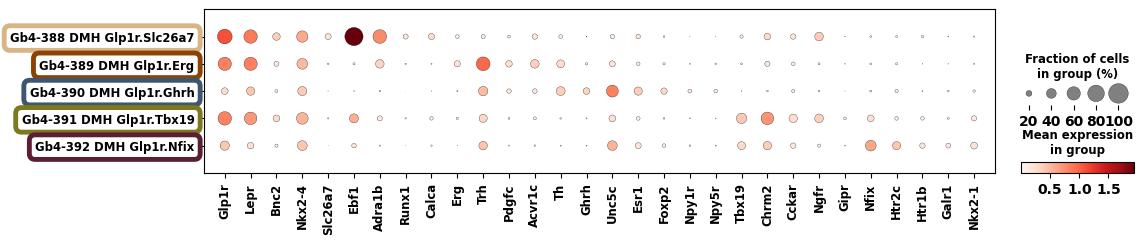

In [9]:
# Compute total height based on number of genes
total_height = 0.425 * len(adata.obs.L4_descr.unique())

# Create DotPlot object with custom height
dotplot_obj = sc.pl.DotPlot(
    adata,
    var_names= gsx1_l4_markers,
    groupby="L4_descr",
    figsize=(12, total_height),  # (width, height)
    cmap='Reds' ,
)


# Create the figure
dotplot_obj.make_figure()

# Access the y-axis
ax = dotplot_obj.ax_dict['mainplot_ax']

# Modify the y-tick labels 
for label in ax.get_yticklabels():
    text = label.get_text()
    color = gsx1_L4_cmap.get(text, "lightgray")  # fallback color
    label.set_bbox(dict(facecolor="white", edgecolor=color, boxstyle='round,pad=0.5',
        linewidth = 3.5))

for label in ax.get_xticklabels():
    label.set_fontweight('bold')
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

cbar_ax = dotplot_obj.fig.axes[-1]
for txt_obj in cbar_ax.texts + cbar_ax.get_yticklabels() + cbar_ax.get_xticklabels():
    txt_obj.set_fontweight('bold')
    txt_obj.set_fontsize(10)

label = cbar_ax.get_ylabel()
if label:
    cbar_ax.set_ylabel(label, fontweight='bold')

label = cbar_ax.get_xlabel()
if label:
    cbar_ax.set_xlabel(label, fontweight='bold')

for text in cbar_ax.texts:
    text.set_fontweight('bold')

for text in dotplot_obj.ax_dict['size_legend_ax'].texts:
    text.set_fontweight('bold')
    

size_legend_ax = dotplot_obj.ax_dict['size_legend_ax']

# Try both x and y tick labels (only one will apply)
for tick in size_legend_ax.get_xticklabels() + size_legend_ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make all text in the figure bold
for text_obj in dotplot_obj.fig.findobj(match=plt.Text):
    if "expression" in text_obj.get_text().lower() or "fraction" in text_obj.get_text().lower():
        text_obj.set_fontweight('bold')
    if text_obj.get_text().lower() in ["20", "40", "60", "80", "100"]:
        text_obj.set_fontsize(10)


plt.savefig(OUTDIR / "dotplot_L4_Gsx_marker.pdf", format="pdf", bbox_inches="tight")

plt.show()